# Space Survival Shooter: evaluation of the RL agent and the rule-based agent

This notebook displays the plots and tables of the final comparison.

**Data (all produced by the project scripts, nothing is typed by hand):**
- `results/test_episodes.csv`: one row per test game and per player (`test.py`)
- `results/test_summary.csv`: one row per player (`test.py`)
- `results/test_paired.csv`: each PPO seed minus the rule-based agent, on the same games (`test.py`)
- `results/seeds_summary.csv` and `results/learning_curves.png`: the training runs (`plot_seeds.py`)

**Evaluation protocol:** 50 test games (seeds 1000-1049), identical for every player.
Training used seeds from 10,000 up, model selection used validation seeds 2000-2009,
and the test seeds were used once, with frozen models.

**How to run:** open this file in VS Code, choose the `.venv` kernel, and press *Run All*.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
os.makedirs("results/figures", exist_ok=True)

episodes = pd.read_csv("results/test_episodes.csv")
summary = pd.read_csv("results/test_summary.csv", index_col=0)
paired = pd.read_csv("results/test_paired.csv")
seeds_table = pd.read_csv("results/seeds_summary.csv")

REFERENCES = ["STAY", "STAY + SHOOT", "RANDOM", "COLUMN SHOOTER"]
PPO_PLAYERS = sorted(p for p in episodes["player"].unique() if p.startswith("PPO"))
PLAYERS = REFERENCES + ["RULE-BASED"] + PPO_PLAYERS


def color_of(player):
    if player in REFERENCES:
        return "#9aa5b1"          # grey: simple reference players
    if player == "RULE-BASED":
        return "#d9822b"          # orange: the hand-made agent
    return "#2b7bd9"              # blue: the RL agents


n_games = episodes.groupby("player").size().iloc[0]
print(f"{len(PLAYERS)} players, {n_games} test games each")

8 players, 50 test games each


## 1. Main results table

Means over the test games. `survived` is the fraction of games not lost (the agent still had a life
when the 5000-step limit was reached). `accuracy` is shots that hit divided by shots fired.
The row *PPO (mean of 3 seeds)* is the average of the three independently trained agents.

In [2]:
columns = ["total_reward", "survival_steps", "survived", "kills", "accuracy",
           "shields_collected", "hits_blocked", "dry_fires", "reward_std"]
display(summary[columns].round(2))

,total_reward,survival_steps,survived,kills,accuracy,shields_collected,hits_blocked,dry_fires,reward_std
player,,,,,,,,,
STAY,-7.31,766.92,0.00,0.00,NaN,0.04,0.04,0.00,1.91
STAY + SHOOT,7.76,1334.44,0.00,5.52,0.13,0.20,0.20,646.24,10.54
RANDOM,11.65,1344.82,0.00,8.88,0.16,0.32,0.32,283.30,13.67
COLUMN SHOOTER,48.48,2631.78,0.00,20.36,0.36,0.48,0.40,39.42,29.90
PPO (ppo_4m_s1),183.95,4448.00,0.58,109.54,0.61,1.60,0.94,1110.02,50.85
PPO (ppo_4m_s2),190.32,4486.66,0.62,113.22,0.63,2.26,1.68,858.82,51.53
RULE-BASED,198.72,5000.00,1.00,99.86,0.56,2.54,0.02,0.00,8.13
PPO (mean of 3 seeds),200.13,4641.53,0.73,117.84,0.64,2.01,1.15,952.03,37.18
PPO (ppo_4m),226.13,4989.92,0.98,130.76,0.67,2.18,0.82,887.24,9.16


## 2. Total reward with its margin of error

The bars show the mean total reward per game. The black lines are the 95% margin of error
(1.96 x standard deviation / square root of the number of games).

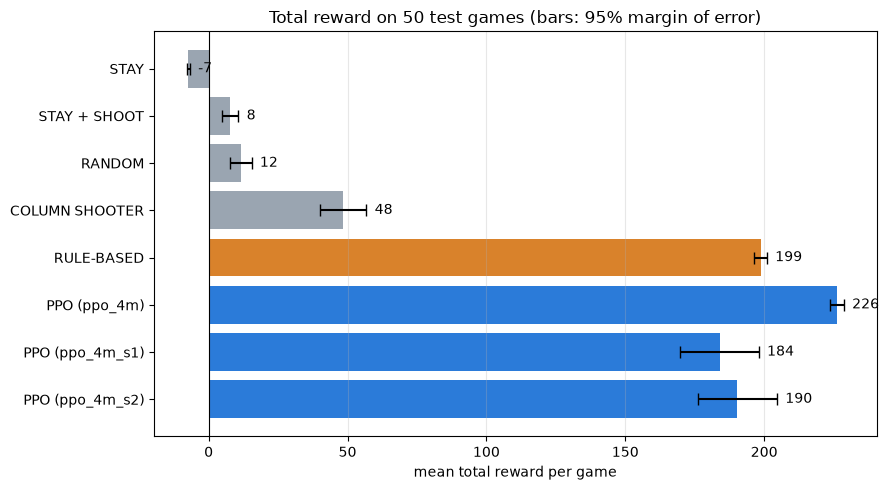

In [3]:
def mean_and_margin(values):
    values = values.dropna()
    return values.mean(), 1.96 * values.std() / np.sqrt(len(values))


stats = {p: mean_and_margin(episodes.loc[episodes["player"] == p, "total_reward"]) for p in PLAYERS}
means = [stats[p][0] for p in PLAYERS]
margins = [stats[p][1] for p in PLAYERS]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(PLAYERS, means, xerr=margins, color=[color_of(p) for p in PLAYERS], capsize=4)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
for y, (m, e) in enumerate(zip(means, margins)):
    ax.text(m + e + 3, y, f"{m:.0f}", va="center")
ax.set_xlabel("mean total reward per game")
ax.set_title(f"Total reward on {n_games} test games (bars: 95% margin of error)")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("results/figures/reward_bars.png", dpi=150)
plt.show()

## 3. How much do the three PPO training runs differ from each other?

A new training run (a new seed) can give a different agent. The standard deviation *between seeds*
tells how much we can trust a single run.

In [4]:
per_seed = episodes[episodes["player"].isin(PPO_PLAYERS)].groupby("player")[
    ["total_reward", "kills", "accuracy", "survived"]].mean()
between = pd.DataFrame({
    "mean": per_seed.mean(),
    "std between seeds": per_seed.std(),
    "min": per_seed.min(),
    "max": per_seed.max(),
})
print("Each PPO seed (means over the test games):")
display(per_seed.round(3))
print("Summary over the seeds:")
display(between.round(3))

Each PPO seed (means over the test games):


,total_reward,kills,accuracy,survived
player,,,,
PPO (ppo_4m),226.129,130.76,0.671,0.98
PPO (ppo_4m_s1),183.950,109.54,0.609,0.58
PPO (ppo_4m_s2),190.317,113.22,0.627,0.62


Summary over the seeds:


,mean,std between seeds,min,max
total_reward,200.132,22.738,183.950,226.129
kills,117.840,11.339,109.540,130.760
accuracy,0.636,0.032,0.609,0.671
survived,0.727,0.220,0.580,0.980


## 4. Several metrics at once

One metric never tells the whole story: the strategies differ in reward, kills, accuracy and safety.

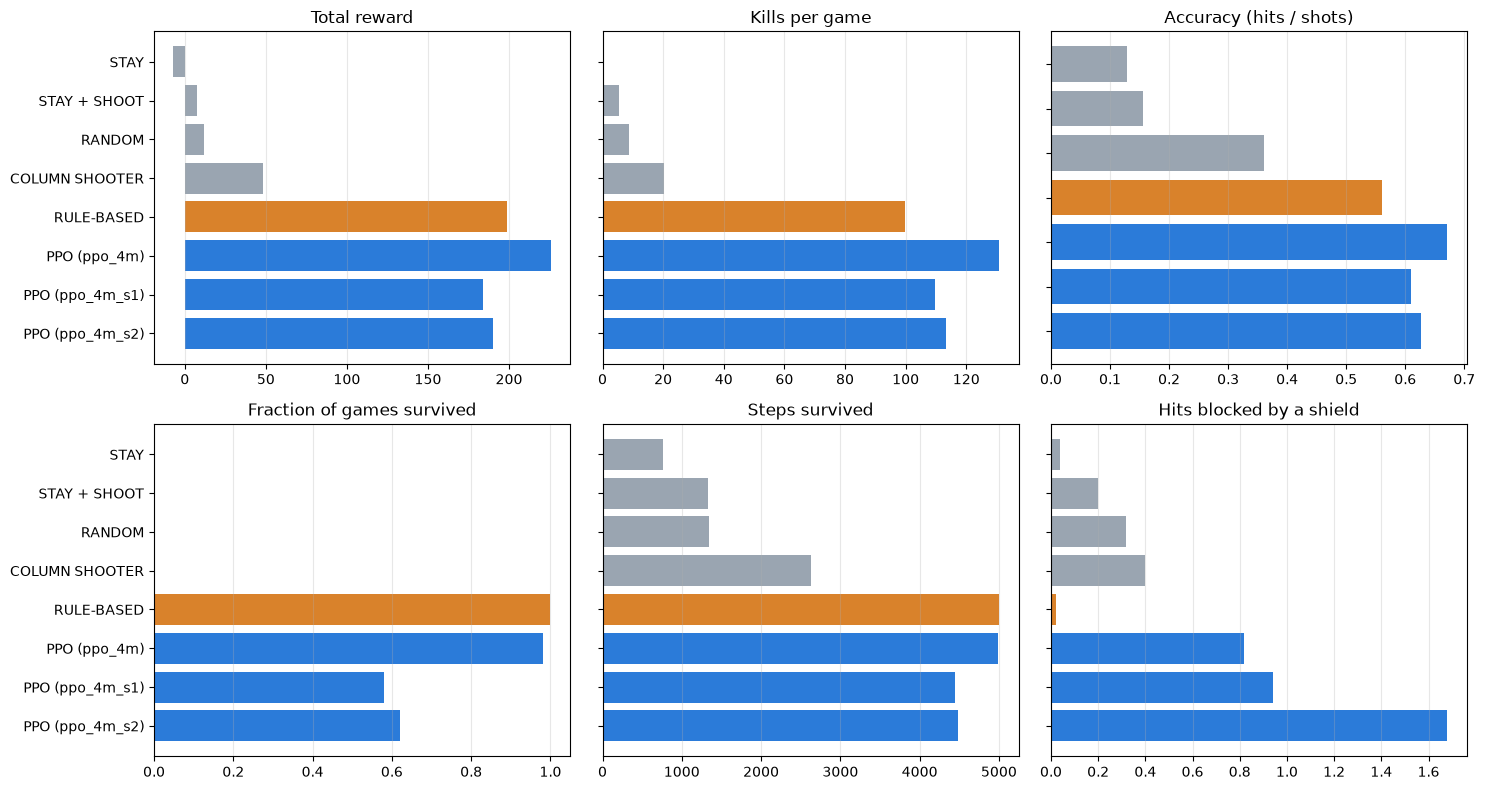

In [5]:
metrics = {
    "total_reward": "Total reward",
    "kills": "Kills per game",
    "accuracy": "Accuracy (hits / shots)",
    "survived": "Fraction of games survived",
    "survival_steps": "Steps survived",
    "hits_blocked": "Hits blocked by a shield",
}
by_player = episodes.groupby("player")[list(metrics)].mean().reindex(PLAYERS)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (ax, (column, title)) in enumerate(zip(axes.ravel(), metrics.items())):
    ax.barh(PLAYERS, by_player[column], color=[color_of(p) for p in PLAYERS])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.3)
    if i % 3 != 0:
        ax.set_yticklabels([])
fig.tight_layout()
fig.savefig("results/figures/metrics_panel.png", dpi=150)
plt.show()

## 5. Distribution of the reward over the games

Each dot is one test game. The box shows the middle half of the games, the line is the median and the
triangle is the mean. A wide box means an unreliable player.

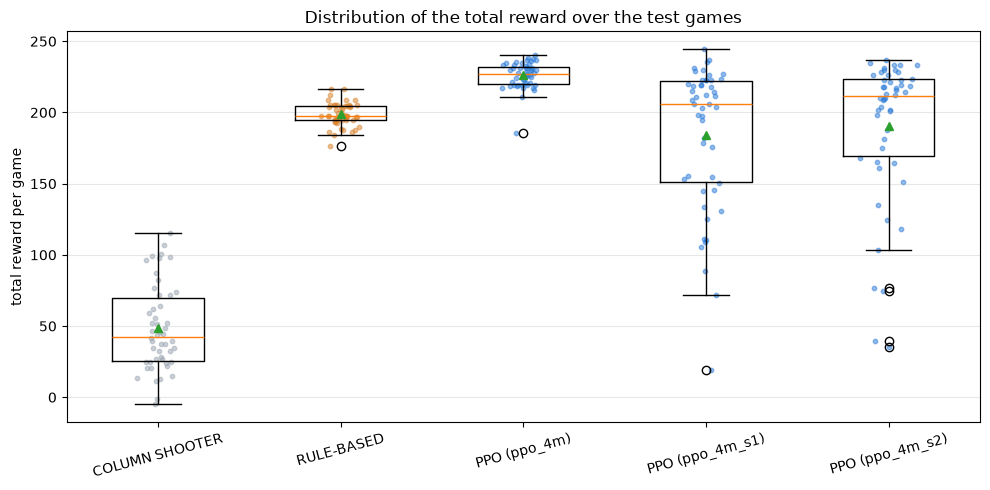

In [6]:
strong = ["COLUMN SHOOTER", "RULE-BASED"] + PPO_PLAYERS
data = [episodes.loc[episodes["player"] == p, "total_reward"] for p in strong]

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(data, showmeans=True)
rng = np.random.default_rng(0)
for i, values in enumerate(data, start=1):
    ax.scatter(rng.normal(i, 0.05, len(values)), values, s=10, alpha=0.5, color=color_of(strong[i - 1]))
ax.set_xticks(range(1, len(strong) + 1))
ax.set_xticklabels(strong, rotation=15)
ax.set_ylabel("total reward per game")
ax.set_title("Distribution of the total reward over the test games")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("results/figures/reward_distribution.png", dpi=150)
plt.show()

## 6. Each PPO seed against the rule-based agent, on the same games

For every game, we subtract the rule-based result from the PPO result, then average.
Using the same games removes the luck of the draw. A dot to the **right of 0 means PPO is better**.
The bar is the 95% margin of error: if it does not cross 0, the difference is real on these games.

,player,metric,mean_difference_vs_rule_based,margin_95,verdict
0,PPO (ppo_4m),total_reward,27.409,2.946,PPO better
1,PPO (ppo_4m),kills,30.900,2.206,PPO better
2,PPO (ppo_4m),survival_steps,-10.080,19.757,no clear difference
3,PPO (ppo_4m),accuracy,0.110,0.008,PPO better
4,PPO (ppo_4m_s1),total_reward,-14.770,14.055,RULE-BASED better
5,PPO (ppo_4m_s1),kills,9.680,7.527,PPO better
6,PPO (ppo_4m_s1),survival_steps,-552.000,244.456,RULE-BASED better
7,PPO (ppo_4m_s1),accuracy,0.049,0.020,PPO better
8,PPO (ppo_4m_s2),total_reward,-8.403,15.326,no clear difference
9,PPO (ppo_4m_s2),kills,13.360,8.511,PPO better


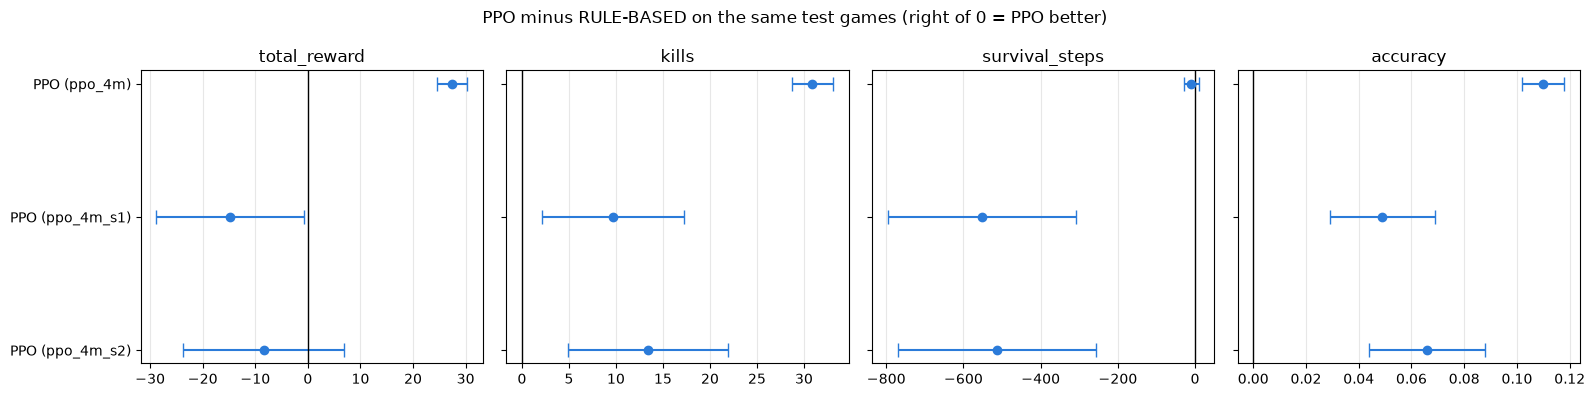

In [7]:
paired["verdict"] = np.where(
    paired["mean_difference_vs_rule_based"] - paired["margin_95"] > 0, "PPO better",
    np.where(paired["mean_difference_vs_rule_based"] + paired["margin_95"] < 0,
             "RULE-BASED better", "no clear difference"))
display(paired)

shown = ["total_reward", "kills", "survival_steps", "accuracy"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, metric in zip(axes, shown):
    part = paired[paired["metric"] == metric].reset_index(drop=True)
    ax.errorbar(part["mean_difference_vs_rule_based"], range(len(part)), xerr=part["margin_95"],
                fmt="o", capsize=5, color="#2b7bd9")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(range(len(part)))
    ax.set_yticklabels(part["player"] if metric == "total_reward" else [])
    ax.invert_yaxis()
    ax.set_title(metric)
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("PPO minus RULE-BASED on the same test games (right of 0 = PPO better)")
fig.tight_layout()
fig.savefig("results/figures/paired_differences.png", dpi=150)
plt.show()

## 7. Training curves of the three seeds

Left: the training reward. Right: the validation reward on 10 fixed games (seeds 2000-2009), with the
mean and the spread of the three seeds, and the rule-based and column-shooter levels as dashed lines.

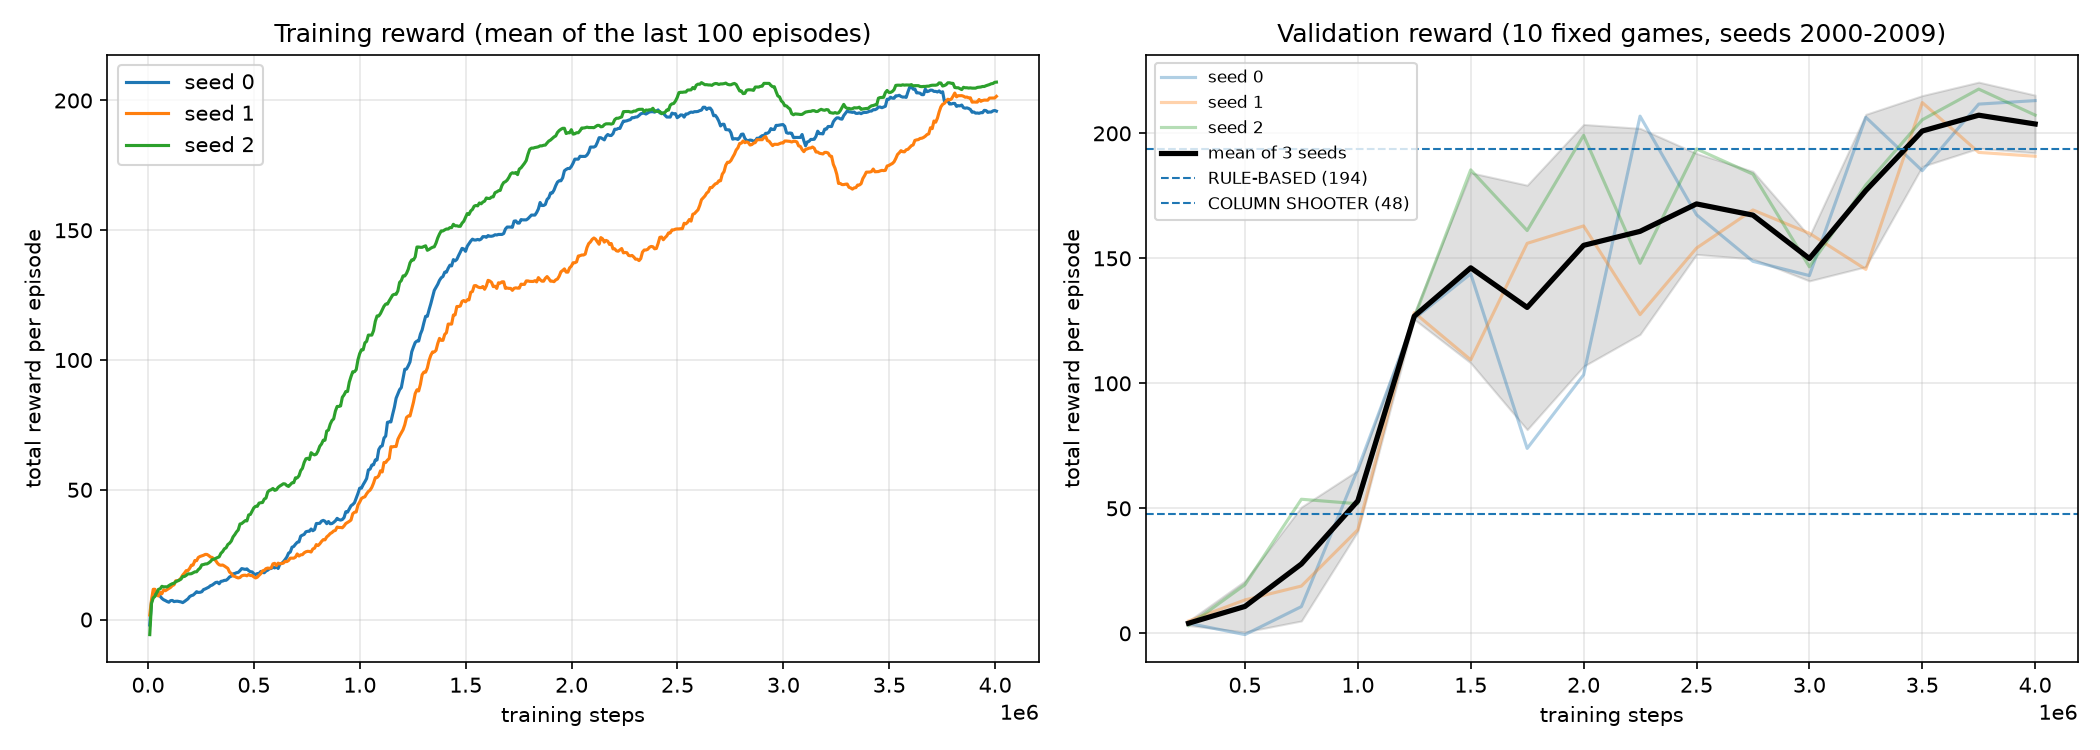

,run,final,mean_last_4,best
0,seed 0,213.1,204.1,213.1
1,seed 1,190.8,185.3,212.3
2,seed 2,207.3,202.4,217.7


In [8]:
display(Image("results/learning_curves.png"))
display(seeds_table)

## 8. Conclusions (complete with your own words)

1. Learning: ...
2. PPO (mean of 3 seeds) compared with the rule-based agent: ...
3. Strategy difference (kills, accuracy, survival): ...
4. Variability between training runs: ...
5. Limits of this study: ...